# 03 Packet-level network simulation of lesion-guided transmission

Each mammogram is cut into 32x32 blocks, every block becomes **one 1060-byte packet**, and the packets go through a simulated network path. The receiver rebuilds the image from whatever arrived **before the deadline**, then runs the localizer ensemble and the classifier on it.

**What changed from the previous 03, and why**
- Before, the "proposed" network itself chose which blocks to lose (lowest priority first). A real channel cannot do that. Now loss is applied to *packets* by a channel model, and priority can act only through things a sender can really do: the **send order**, **where the protection budget is spent** (FEC / retransmission), and **which packets a congested queue drops** (the last ones sent).
- Every strategy gets the **same overhead budget** (extra packets = rho x number of blocks). Uniform strategies also get FEC and ARQ, so any gain comes from clinical guidance, not from extra protection.
- Burst loss now applies to every strategy (Gilbert-Elliott channel); before it affected only the uniform one.
- Delay, jitter, goodput and loss are **measured from the simulated packets** (serialisation, queueing, propagation, jitter) instead of being computed from the input parameters.

```
image -> 32x32 blocks -> priority ranking (lesion map + classifier saliency)
      -> packets (1 block = 1 datagram, 1060 B)
      -> sender pacing -> bottleneck FIFO queue (tail drop) -> lossy last hop (iid / Gilbert-Elliott)
      -> + propagation delay + jitter -> receiver (block usable only if available before the deadline)
      <- NACK (ARQ strategies only)
receiver: reconstruct (mean fill) -> localizer ensemble -> lesion crop -> classifier
```

**Strategies** (same overhead budget for all protected ones)

| name | send order | protection |
|---|---|---|
| Uniform | random | none |
| Uniform+FEC | random | parity spread evenly: groups of 16 blocks, same total parity |
| Uniform+ARQ | random | retransmit missing blocks in random order, same packet budget |
| Proposed | by clinical priority | none |
| Proposed+UEP-FEC | by clinical priority | whole parity budget on the top-ranked blocks (k=4, r=4) |
| Proposed+sel-ARQ | by clinical priority | retransmit missing blocks, most important first, same budget |

Ablations (section 6) swap the priority source: *Conventional* (block contrast, not clinical) and *Oracle* (true lesion mask).

**Scenarios (sweeps)**: random loss, bursty loss, congestion (sender faster than the bottleneck), bandwidth + deadline, long delay + jitter (where ARQ should fail), a combined mobile-like profile, and the overhead budget itself.

**What this still is not.** It is a simulation: no TCP/QUIC or congestion control, fixed pacing, NACKs never lost, an idealised erasure code (a group decodes if at least k of its k+r packets arrive), and standard but synthetic loss models. Section 8 lists what to do to validate it on an emulator.

In [1]:
from google.colab import drive; drive.mount("/content/drive")
import glob, os, sys, json, time
hits = glob.glob("/content/drive/MyDrive/mammo_semcom/**/src/config.py", recursive=True)
CODE_DIR = os.path.dirname(os.path.dirname(hits[0])); WORK_DIR = "/content/drive/MyDrive/mammo_semcom_work"
sys.path.insert(0, CODE_DIR); print("code:", CODE_DIR)
import numpy as np, pandas as pd, cv2, matplotlib
import matplotlib.pyplot as plt
from collections import deque
from src.config import Cfg
from src import data
from src.train import to01
from src.pipeline import build_importance, diagnose_all
from src.metrics import auc_safe, roi_bbox, roi_psnr, bootstrap_ci, paired_bootstrap_diff
from src.channel import apply_loss
from src.train_v2 import load_classifier_v2, load_localizer_v2, ReceiverV2
from src.tx_v2 import importance_sets

# ------------------------------------------------------------------ experiment size (runtime: ~30-60 min on a T4 with the defaults)
N_EVAL       = 0      # test images (0 = whole test set). 100 is enough for the curves; use 0 for final numbers
REPS         = 1        # repeats of every random network realisation (use 3 for final numbers)
M_SEEDS      = 3        # localizer ensemble size
RHO          = 0.20     # protection budget: extra packets = RHO x number of blocks (identical for every strategy)
BURST_LEN    = 8.0      # mean burst length in packets of the Gilbert-Elliott channel
LOSS         = (.1, .2, .3, .4, .5)
RUN_RECEIVER = True     # False = network metrics only (fast, no classification)
SWEEPS       = ("iid", "burst", "congestion", "deadline", "rtt", "combined", "overhead", "ablation")
RESUME       = True     # reuse the CSV of a finished sweep (delete results/net3_*.csv to rerun)

Mounted at /content/drive
code: /content/drive/MyDrive/mammo_semcom


In [2]:
cfg = Cfg(work_dir=WORK_DIR).ensure()
images, masks, images_df, abn_df = data.load_cache(cfg)
heat = np.load(cfg.path("cache", "heatmaps_v2.npy"), mmap_mode="r")
lm = json.load(open(cfg.path("models", "loc_v2.json")))
localizers = [load_localizer_v2(cfg, f"v2_s{s}", lm["act"]) for s in range(M_SEEDS)]
clf, cmeta = load_classifier_v2(cfg)
receiver = ReceiverV2(cfg, localizers, clf, sigma=lm["sigma"])
THR = cmeta["thr"]

te = images_df[(images_df.split == "test") & (~images_df.mixed)]            # mixed-label images are excluded (as before)
te = te.iloc[:N_EVAL] if N_EVAL else te
ids = te.img_idx.values; meta = te[["patient_id", "label"]].reset_index(drop=True)
imgs_u8, masks_u8 = images[ids], masks[ids]
img01 = np.stack([to01(a) for a in imgs_u8]); heats = [np.asarray(heat[i], np.float32) for i in ids]
N = len(ids); Y = meta.label.values; PAT = meta.patient_id.values; BLK = cfg.block
print("test images:", N, "| classifier mode:", cmeta.get("mode"), "| threshold", round(THR, 3))

# block priorities (sender side)
c = importance_sets(cfg, img01, heats, clf)                                  # none / conventional / clinical (map + saliency)
IMPS = {"none": c["none"], "conventional": c["conventional"], "clinical": c["clinical"],
        "oracle": [a.astype(np.float32) for a in build_importance(cfg, imgs_u8, masks_u8, heats, "oracle")]}
GT = [m > 0 for m in masks_u8]; BBOX = [roi_bbox(g) for g in GT]
_k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (49, 49)); GTD = [cv2.dilate(g.astype(np.uint8), _k) > 0 for g in GT]
TX = [a >= 0 for a in IMPS["none"]]
LES = [m[:t.shape[0] * BLK, :t.shape[1] * BLK].reshape(t.shape[0], BLK, t.shape[1], BLK).any((1, 3)) & t for m, t in zip(GT, TX)]
print("blocks sent per image (median):", int(np.median([t.sum() for t in TX])), "| lesion blocks per image (median):", int(np.median([l.sum() for l in LES])))

test images: 453 | classifier mode: pheno | threshold 0.347


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:1072: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:410.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


blocks sent per image (median): 236 | lesion blocks per image (median): 6


## 1. The network simulator
Pure numpy, about 2 ms per image. `Path` is the network (pacing, bottleneck queue, lossy hop, delay and jitter). `transmit` sends one image with a chosen send order and protection scheme and returns which blocks were usable before the deadline, when each became available, and measured packet statistics.

In [3]:
import numpy as np
from collections import deque

PKT_PAYLOAD, PKT_HDR = 1024, 36            # one 32x32 uint8 block per packet; IPv4(20)+UDP(8)+app header(8)
PKT_BYTES = PKT_PAYLOAD + PKT_HDR

BASE = dict(loss_model="iid",   # "iid" = Bernoulli loss, "ge" = Gilbert-Elliott (bursty)
            loss=0.0,           # average packet loss probability of the last hop
            burst_len=8.0,      # mean burst length in packets (Gilbert-Elliott only)
            send_pps=1200.0,    # sender pacing rate, packets/s (about 10 Mbit/s with 1060-byte packets)
            link_pps=1200.0,    # bottleneck service rate, packets/s
            buf=30,             # bottleneck buffer in packets (FIFO, tail drop)
            owd=0.025,          # one-way propagation delay, s
            jitter=0.005,       # mean of the exponential delay noise, s
            deadline=2.0,       # a block is useful only if it is available before this time, s
            rho=0.20,           # protection budget: extra packets = rho x number of blocks
            arq_rounds=2)       # maximum number of retransmission rounds


class Path:
    """Sender pacing -> bottleneck FIFO queue (tail drop) -> lossy last hop (iid or Gilbert-Elliott) -> delay + jitter."""

    def __init__(self, sc, rng, trace=False):
        self.sc, self.rng, self.trace = sc, rng, trace
        self.q, self.last_dep, self.t_send, self.bad, self.qtrace = deque(), 0.0, 0.0, False, []
        gl, bl = float(sc["loss"]), max(float(sc["burst_len"]), 1.0)
        self.p_bg = 1.0 / bl                                          # bad -> good
        self.p_gb = self.p_bg * gl / (1 - gl) if gl < 1 else 1.0      # good -> bad  (stationary P(bad) = gl)
        self._redraw()

    def _redraw(self):
        if self.sc["loss_model"] == "ge":
            self.bad = self.rng.random() < self.sc["loss"]

    def begin(self, t0):
        """Start a new burst of packets at time t0 (e.g. a retransmission round). The channel state is decorrelated."""
        self.t_send = max(self.t_send, t0)
        self._redraw()

    def send(self):
        """Send one packet. Returns (send_time, arrival_time or inf, 'ok' | 'queue' | 'channel')."""
        sc, rng = self.sc, self.rng
        ts = self.t_send; self.t_send += 1.0 / sc["send_pps"]
        while self.q and self.q[0] <= ts:
            self.q.popleft()
        if self.trace:
            self.qtrace.append((ts, len(self.q)))
        if len(self.q) >= sc["buf"]:
            return ts, np.inf, "queue"
        dep = max(ts, self.last_dep) + 1.0 / sc["link_pps"]
        self.last_dep = dep; self.q.append(dep)
        if sc["loss_model"] == "ge":
            if self.bad:
                if rng.random() < self.p_bg: self.bad = False
            elif rng.random() < self.p_gb:
                self.bad = True
            lost = self.bad
        else:
            lost = rng.random() < sc["loss"]
        if lost:
            return ts, np.inf, "channel"
        return ts, dep + sc["owd"] + (rng.exponential(sc["jitter"]) if sc["jitter"] > 0 else 0.0), "ok"


# ------------------------------------------------------------------ protection plans
def _groups_uep(order, P, K=4):
    """Unequal error protection: the whole parity budget goes to the top-ranked blocks, rate-1/2 code (r = k)."""
    m = int(min(len(order), P)); prot = list(order[:m])
    groups = [dict(data=prot[i:i + K], r=len(prot[i:i + K])) for i in range(0, m, K)]
    return groups, list(order[m:])


def _groups_even(order, P, K=16):
    """Equal error protection: groups of K blocks, the same total parity budget spread evenly over all of them."""
    order = list(order)
    G = int(np.ceil(len(order) / K))
    if G == 0:
        return [], []
    base, extra = divmod(int(P), G)
    return [dict(data=order[i * K:(i + 1) * K], r=base + (1 if i < extra else 0)) for i in range(G)], []


def _emit(groups, plain, depth=8):
    """Packet sequence. Groups are interleaved in super-frames of `depth` groups so that a burst hits each group only once."""
    seq = []
    for s in range(0, len(groups), depth):
        sf = groups[s:s + depth]
        L = max(len(g["data"]) + g["r"] for g in sf)
        for j in range(L):
            for gi, g in enumerate(sf):
                k = len(g["data"])
                if j < k: seq.append(("d", g["data"][j], s + gi))
                elif j < k + g["r"]: seq.append(("p", -1, s + gi))
    return seq + [("d", b, -1) for b in plain]


def transmit(imp, order_mode, protect, sc, rng, trace=False):
    """Send one image. imp >= 0: block is sent (value = priority), -1: not sent.
    order_mode: 'shuffle' (random order, no knowledge) | 'priority' (highest priority first)
    protect   : 'none' | 'fec_even' | 'fec_uep' | 'arq'
    Returns dict(recv, t_avail, stats, order, P, qtrace)."""
    flat = np.asarray(imp, float).ravel(); idx = np.flatnonzero(flat >= 0); n = len(idx)
    t_avail = np.full(flat.size, np.inf)
    if n == 0:
        return dict(recv=np.zeros(imp.shape, bool), t_avail=t_avail.reshape(imp.shape), stats={}, order=idx, P=0, qtrace=[])
    order = idx[np.lexsort((rng.random(n), -flat[idx]))] if order_mode == "priority" else rng.permutation(idx)
    P = int(round(sc["rho"] * n)) if protect != "none" else 0
    if protect == "fec_uep":   groups, plain = _groups_uep(order, P)
    elif protect == "fec_even": groups, plain = _groups_even(order, P)
    else:                      groups, plain = [], list(order)
    seq = _emit(groups, plain)
    path = Path(sc, rng, trace)
    log = []                                                    # (kind, id, group, send time, arrival, why)
    garr = {}                                                   # group -> arrival times of its delivered packets

    def push(kind, ident, grp):
        ts, arr, why = path.send(); log.append((kind, ident, grp, ts, arr, why))
        if np.isfinite(arr):
            if kind in ("d", "r"): t_avail[ident] = min(t_avail[ident], arr)
            if grp >= 0: garr.setdefault(grp, []).append(arr)

    for kind, ident, grp in seq:
        push(kind, ident, grp)
    for g, mem in enumerate(groups):                            # erasure decoding (idealised MDS code, e.g. Reed-Solomon)
        k = len(mem["data"]); a = np.sort(garr.get(g, []))
        if len(a) >= k > 0:
            for b in mem["data"]:
                t_avail[b] = min(t_avail[b], a[k - 1])
    if protect == "arq":                                        # selective retransmission of the still-missing blocks
        budget = P
        for _ in range(sc["arq_rounds"]):
            miss = [b for b in order if not np.isfinite(t_avail[b])]
            if not miss or budget <= 0:
                break
            t_nack = path.last_dep + 2 * sc["owd"] + 3 * sc["jitter"]     # receiver notices the gap, NACK travels back
            if t_nack + sc["owd"] >= sc["deadline"]:
                break
            retx = miss[:budget]; path.begin(t_nack)
            for b in retx:
                push("r", b, -1)
            budget -= len(retx)

    recv_flat = t_avail <= sc["deadline"]
    kinds = np.array([r[0] for r in log]); ts_ = np.array([r[3] for r in log]); arr_ = np.array([r[4] for r in log])
    why = np.array([r[5] for r in log]); ok = np.isfinite(arr_); tr = (arr_ - ts_)[ok]
    got = t_avail[idx][recv_flat[idx]]; comp = float(got.max()) if got.size else np.nan
    stats = dict(pkts_sent=len(log), overhead=float(((kinds == "p") | (kinds == "r")).sum() / n),
                 pkt_loss=float((~ok).mean()), queue_drops=int((why == "queue").sum()), late_pkts=int((arr_[ok] > sc["deadline"]).sum()),
                 block_delivery=float(recv_flat[idx].mean()),
                 delay_ms=float(1e3 * tr.mean()) if tr.size else np.nan,
                 p95_delay_ms=float(1e3 * np.percentile(tr, 95)) if tr.size else np.nan,
                 jitter_ms=float(1e3 * np.abs(np.diff(tr)).mean()) if tr.size > 1 else np.nan,
                 completion_s=comp, goodput_KBps=float(recv_flat[idx].sum() * PKT_PAYLOAD / 1024 / comp) if comp and comp > 0 else np.nan)
    return dict(recv=recv_flat.reshape(imp.shape), t_avail=t_avail.reshape(imp.shape), stats=stats, order=order, P=P, qtrace=path.qtrace)


S = lambda **kw: {**BASE, "rho": RHO, "burst_len": BURST_LEN, **kw}      # scenario = BASE + overrides

### Sanity checks of the simulator (toy image)
The checks assert the properties the experiments rely on. If one fails the notebook stops here.

In [4]:
rng0 = np.random.default_rng(0)
toy = np.full((24, 16), -1.0); toy[:, :10] = rng0.random((24, 10)) * .5
toy_les = np.zeros((24, 16), bool); toy_les[8:13, 3:8] = True
near_ = np.zeros_like(toy_les); near_[6:15, 1:10] = True
toy[near_] = 1 + .9 * rng0.random(near_.sum()); toy[toy_les] = 2.5 + .9 * rng0.random(toy_les.sum())
CHK = {"Uniform": ("shuffle", "none"), "Uniform+FEC": ("shuffle", "fec_even"), "Uniform+ARQ": ("shuffle", "arq"),
       "Proposed": ("priority", "none"), "Proposed+UEP-FEC": ("priority", "fec_uep"), "Proposed+sel-ARQ": ("priority", "arq")}

def check(sc, reps=100):
    out = {}
    for name, (om, pr) in CHK.items():
        r = [transmit(toy, om, pr, sc, np.random.default_rng(k)) for k in range(reps)]
        out[name] = dict(blocks=np.mean([x["stats"]["block_delivery"] for x in r]), lesion=np.mean([x["recv"][toy_les].mean() for x in r]),
                         overhead=np.mean([x["stats"]["overhead"] for x in r]))
    return pd.DataFrame(out).T.round(3)

# channel statistics: loss rate and mean burst length of the iid and Gilbert-Elliott models
def chan_stats(model, loss, n=200000):
    p = Path(S(loss_model=model, loss=loss, buf=10**9, send_pps=1e9, link_pps=1e9, jitter=0), np.random.default_rng(1))
    lost = np.array([p.send()[2] != "ok" for _ in range(n)]); e = np.diff(np.r_[0, lost.astype(int), 0]); runs = np.flatnonzero(e == -1) - np.flatnonzero(e == 1)
    return lost.mean(), runs.mean()
for model in ("iid", "ge"):
    lr, bl = chan_stats(model, .3); print(f"{model:3s}: loss {lr:.3f} (target .30) | mean burst {bl:.2f} packets")
    assert abs(lr - .3) < .015
assert abs(chan_stats("iid", .3)[1] - 1 / .7) < .1 and abs(chan_stats("ge", .3)[1] - BURST_LEN) < .6

ideal = check(S()); display(ideal.rename_axis("ideal link"))
assert (ideal.blocks == 1).all() and abs(ideal.loc["Uniform+FEC", "overhead"] - RHO) < .01 and ideal.loc["Uniform+ARQ", "overhead"] == 0
iid = check(S(loss_model="iid", loss=.3)); display(iid.rename_axis("random loss 30%"))
assert abs(iid.loc["Proposed", "lesion"] - iid.loc["Uniform", "lesion"]) < .06                 # send order alone does not help against random loss
assert iid.loc["Proposed+UEP-FEC", "lesion"] > iid.loc["Proposed", "lesion"] + .15              # UEP protects the lesion
assert iid.loc["Proposed+sel-ARQ", "lesion"] > iid.loc["Uniform+ARQ", "lesion"] + .03           # same budget, better targeted
far = check(S(loss_model="ge", loss=.2, owd=.5, jitter=.06, deadline=1.5)); display(far.rename_axis("RTT 1 s, deadline 1.5 s"))
assert abs(far.loc["Uniform+ARQ", "blocks"] - far.loc["Uniform", "blocks"]) < .03                # ARQ cannot finish in time on a long path
cong = check(S(link_pps=.5 * BASE["send_pps"])); display(cong.rename_axis("congestion: bottleneck = 50% of the sending rate"))
assert cong.loc["Proposed", "lesion"] > .98 and cong.loc["Uniform", "lesion"] < .75             # tail drop hits the packets sent last
print("simulator checks passed")

iid: loss 0.300 (target .30) | mean burst 1.43 packets
ge : loss 0.303 (target .30) | mean burst 8.16 packets


,blocks,lesion,overhead
ideal link,,,
Uniform,1.0,1.0,0.0
Uniform+FEC,1.0,1.0,0.2
Uniform+ARQ,1.0,1.0,0.0
Proposed,1.0,1.0,0.0
Proposed+UEP-FEC,1.0,1.0,0.2
Proposed+sel-ARQ,1.0,1.0,0.0


,blocks,lesion,overhead
random loss 30%,,,
Uniform,0.701,0.706,0.0
Uniform+FEC,0.724,0.729,0.2
Uniform+ARQ,0.842,0.851,0.2
Proposed,0.703,0.705,0.0
Proposed+UEP-FEC,0.755,0.968,0.2
Proposed+sel-ARQ,0.843,0.912,0.2


,blocks,lesion,overhead
"RTT 1 s, deadline 1.5 s",,,
Uniform,0.791,0.805,0.0
Uniform+FEC,0.845,0.846,0.2
Uniform+ARQ,0.791,0.805,0.0
Proposed,0.795,0.818,0.0
Proposed+UEP-FEC,0.831,0.985,0.2
Proposed+sel-ARQ,0.795,0.818,0.0


,blocks,lesion,overhead
congestion: bottleneck = 50% of the sending rate,,,
Uniform,0.621,0.629,0.0
Uniform+FEC,0.662,0.650,0.2
Uniform+ARQ,0.821,0.833,0.2
Proposed,0.621,1.000,0.0
Proposed+UEP-FEC,0.600,1.000,0.2
Proposed+sel-ARQ,0.821,1.000,0.2


simulator checks passed


### Figure 1: what the channel and the queue do

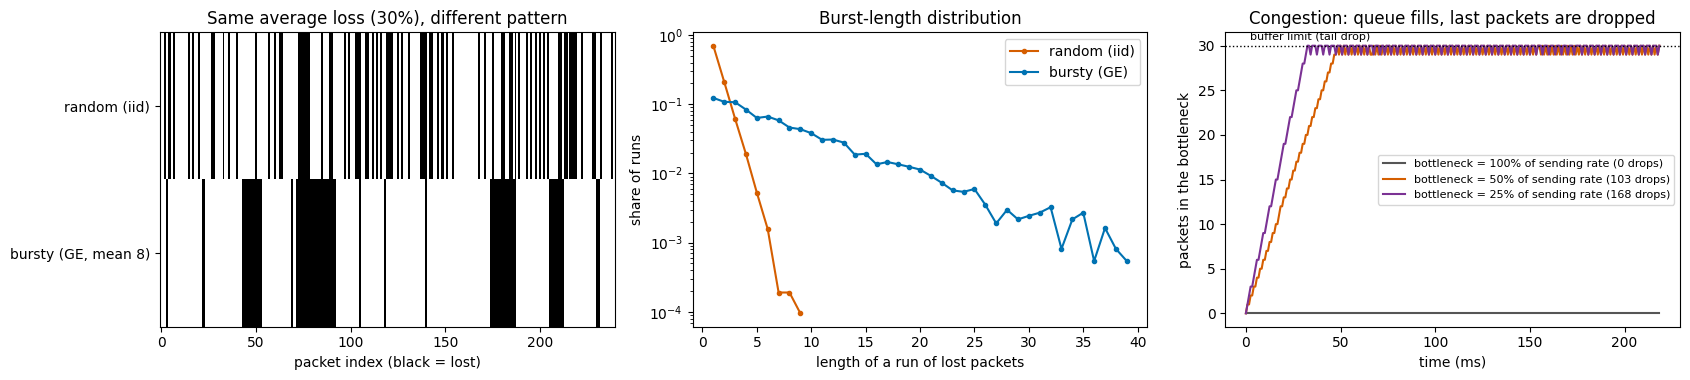

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 3.9))
ev = []
for model in ("iid", "ge"):
    p = Path(S(loss_model=model, loss=.3, buf=10**9, send_pps=1e9, link_pps=1e9), np.random.default_rng(5))
    ev.append([p.send()[2] != "ok" for _ in range(240)])
ax[0].imshow(np.array(ev, float), aspect="auto", cmap="Greys", interpolation="nearest")
ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["random (iid)", f"bursty (GE, mean {BURST_LEN:.0f})"]); ax[0].set_xlabel("packet index (black = lost)")
ax[0].set_title("Same average loss (30%), different pattern")
for model, col in (("iid", "#D55E00"), ("ge", "#0072B2")):
    p = Path(S(loss_model=model, loss=.3, buf=10**9, send_pps=1e9, link_pps=1e9), np.random.default_rng(6))
    l = np.array([p.send()[2] != "ok" for _ in range(100000)]); e = np.diff(np.r_[0, l.astype(int), 0]); runs = np.flatnonzero(e == -1) - np.flatnonzero(e == 1)
    h = np.bincount(runs)[1:40] / len(runs); ax[1].plot(np.arange(1, len(h) + 1), h, marker="o", ms=3, color=col, label="random (iid)" if model == "iid" else "bursty (GE)")
ax[1].set_yscale("log"); ax[1].set_xlabel("length of a run of lost packets"); ax[1].set_ylabel("share of runs"); ax[1].legend(); ax[1].set_title("Burst-length distribution")
ex = int(np.argsort([l.sum() for l in LES])[N // 2])
for frac, col in ((1.0, "#555555"), (.5, "#D55E00"), (.25, "#7B3294")):
    r = transmit(IMPS["clinical"][ex], "priority", "none", S(link_pps=frac * BASE["send_pps"]), np.random.default_rng(0), trace=True)
    q = np.array(r["qtrace"]); ax[2].plot(q[:, 0] * 1e3, q[:, 1], color=col, label=f"bottleneck = {frac:.0%} of sending rate ({r['stats']['queue_drops']} drops)")
ax[2].axhline(BASE["buf"], color="k", ls=":", lw=1); ax[2].text(2, BASE["buf"] + .6, "buffer limit (tail drop)", fontsize=8)
ax[2].set_xlabel("time (ms)"); ax[2].set_ylabel("packets in the bottleneck"); ax[2].legend(fontsize=8); ax[2].set_title("Congestion: queue fills, last packets are dropped")
plt.tight_layout(); plt.savefig(cfg.path("figures", "net3_fig1_channel.png"), dpi=150); plt.show()

## 2. Experiment runner
For every scenario and strategy: simulate the transmission of each test image, rebuild the damaged image (lost blocks filled with the mean intensity), and (optionally) run the receiver. The same random seeds are used for every strategy of a scenario, so comparisons are paired.

In [6]:
STRATS = {   # name: (importance source, send order, protection)
    "Uniform": ("none", "shuffle", "none"), "Uniform+FEC": ("none", "shuffle", "fec_even"), "Uniform+ARQ": ("none", "shuffle", "arq"),
    "Proposed": ("clinical", "priority", "none"), "Proposed+UEP-FEC": ("clinical", "priority", "fec_uep"), "Proposed+sel-ARQ": ("clinical", "priority", "arq"),
    "Conventional+UEP-FEC": ("conventional", "priority", "fec_uep"), "Oracle+UEP-FEC": ("oracle", "priority", "fec_uep"),
    "Conventional+sel-ARQ": ("conventional", "priority", "arq"), "Oracle+sel-ARQ": ("oracle", "priority", "arq")}
MAIN = list(STRATS)[:6]
ABL = ["Uniform+FEC", "Proposed+UEP-FEC", "Conventional+UEP-FEC", "Oracle+UEP-FEC", "Uniform+ARQ", "Proposed+sel-ARQ", "Conventional+sel-ARQ", "Oracle+sel-ARQ"]

SWEEP_DEF = {   # sweep -> [(x, scenario)]
    "iid":        [(p, S(loss_model="iid", loss=p)) for p in LOSS],
    "burst":      [(p, S(loss_model="ge", loss=p)) for p in LOSS],
    "congestion": [(c_, S(link_pps=c_ * BASE["send_pps"])) for c_ in (1.0, .7, .5, .35, .25)],
    "deadline":   [(bw, S(send_pps=bw, link_pps=bw, deadline=.5)) for bw in (1200, 600, 400, 300, 200)],
    "rtt":        [(2000 * o, S(loss_model="ge", loss=.2, owd=o, jitter=.01 + .1 * o, deadline=1.5)) for o in (.01, .05, .15, .3, .5)],
    "combined":   [(0, S(loss_model="ge", loss=.2, link_pps=.7 * BASE["send_pps"], owd=.06, jitter=.03, deadline=1.5))],
    "overhead":   [(r_, S(loss_model="ge", loss=.3, rho=r_)) for r_ in (0, .1, .2, .3, .5)],
    "ablation":   [(0, S(loss_model="ge", loss=.3))]}
NETCOLS = ["lesion_delivery", "block_delivery", "lesion_loss", "roi_psnr", "tier_recall", "overhead", "pkt_loss", "delay_ms", "p95_delay_ms",
           "jitter_ms", "goodput_KBps", "completion_s", "lesion_time_s", "queue_drops", "late_pkts"]

def run_condition(sweep, x, sc, strat, tag, reps=REPS):
    src, order_mode, prot = STRATS[strat]; rows = []
    for rep in range(reps):
        dmg = np.empty_like(img01); per = []
        for i in range(N):
            imp = IMPS[src][i]; res = transmit(imp, order_mode, prot, sc, np.random.default_rng([cfg.seed, rep, i, tag]))
            sent, recv, les = imp >= 0, res["recv"], LES[i]
            dmg[i], pix = apply_loss(img01[i], sent & ~recv, BLK, cfg.recon)
            lt = res["t_avail"][les & recv]; tier = np.nan
            if order_mode == "priority" and les.any():                                   # how many lesion blocks sit in the protected tier
                tier = np.isin(np.flatnonzero(les.ravel()), res["order"][:int(round(sc["rho"] * sent.sum()))]).mean()
            per.append(dict(sweep=sweep, x=x, strategy=strat, rep=rep, img=i, patient_id=PAT[i], y=int(Y[i]),
                            lesion_delivery=recv[les].mean() if les.any() else np.nan, lesion_loss=(pix & GT[i]).sum() / max(GT[i].sum(), 1),
                            lesion_time_s=lt.max() if lt.size else np.nan, tier_recall=tier,
                            roi_psnr=roi_psnr(img01[i], dmg[i], BBOX[i]) if BBOX[i] else np.nan, **res["stats"]))
        if RUN_RECEIVER:
            r = diagnose_all(receiver, dmg)
            for i, d in enumerate(per):
                d["p"] = float(r["p"][i]); d["hit"] = bool(GTD[i][int(round(r["cy"][i])), int(round(r["cx"][i]))])
        rows += per
    return rows

def run_sweep(name):
    path = cfg.path("results", f"net3_{name}.csv")
    if RESUME and os.path.exists(path):
        print(f"[{name}] reusing {path}"); return pd.read_csv(path)
    rows, t0 = [], time.time()
    for j, (x, sc) in enumerate(SWEEP_DEF[name]):
        for strat in (ABL if name == "ablation" else MAIN):
            rows += run_condition(name, x, sc, strat, tag=1000 * list(SWEEP_DEF).index(name) + j)
        print(f"[{name}] x={x} done ({time.time() - t0:.0f}s)")
    df = pd.DataFrame(rows); df.to_csv(path, index=False); return df

if RUN_RECEIVER:                                              # reference: the receiver gets every block
    rc = diagnose_all(receiver, img01)
    CLEAN_AUC = auc_safe(Y, rc["p"]); CLEAN_HIT = float(np.mean([GTD[i][int(round(rc["cy"][i])), int(round(rc["cx"][i]))] for i in range(N)]))
    print(f"complete image (no network): AUC {CLEAN_AUC:.3f} | localization hit-rate {CLEAN_HIT:.3f}")
else:
    CLEAN_AUC = CLEAN_HIT = np.nan

complete image (no network): AUC 0.700 | localization hit-rate 0.578


## 3. Run all sweeps

In [7]:
R = pd.concat([run_sweep(s) for s in SWEEPS], ignore_index=True)

def summarize(R):
    rows = []
    for (sw, x, st), d in R.groupby(["sweep", "x", "strategy"], sort=False):
        o = dict(sweep=sw, x=x, strategy=st)
        if RUN_RECEIVER and "p" in d:
            a = np.array([auc_safe(g.y.values, g.p.values) for _, g in d.groupby("rep")])
            o.update(AUC=np.nanmean(a), AUC_sd=np.nanstd(a), ACC=float(((d.p >= THR) == d.y).mean()), loc_hit=float(d.hit.mean()))
        o.update({k: d[k].mean() for k in NETCOLS if k in d})
        rows.append(o)
    return pd.DataFrame(rows)

SUM = summarize(R); SUM.to_csv(cfg.path("results", "net3_summary.csv"), index=False)
print(len(R), "per-image rows |", SUM.groupby("sweep").size().to_dict(), "conditions per sweep")

[iid] x=0.1 done (217s)
[iid] x=0.2 done (432s)
[iid] x=0.3 done (646s)
[iid] x=0.4 done (857s)
[iid] x=0.5 done (1066s)
[burst] x=0.1 done (215s)
[burst] x=0.2 done (430s)
[burst] x=0.3 done (642s)
[burst] x=0.4 done (852s)
[burst] x=0.5 done (1060s)
[congestion] x=1.0 done (210s)
[congestion] x=0.7 done (421s)
[congestion] x=0.5 done (629s)
[congestion] x=0.35 done (837s)
[congestion] x=0.25 done (1041s)
[deadline] x=1200 done (211s)
[deadline] x=600 done (422s)
[deadline] x=400 done (631s)
[deadline] x=300 done (837s)
[deadline] x=200 done (1043s)
[rtt] x=20.0 done (213s)
[rtt] x=100.0 done (425s)
[rtt] x=300.0 done (639s)
[rtt] x=600.0 done (854s)
[rtt] x=1000.0 done (1068s)
[combined] x=0 done (210s)
[overhead] x=0 done (210s)
[overhead] x=0.1 done (421s)
[overhead] x=0.2 done (633s)
[overhead] x=0.3 done (845s)
[overhead] x=0.5 done (1059s)
[ablation] x=0 done (284s)
87882 per-image rows | {'ablation': 8, 'burst': 30, 'combined': 6, 'congestion': 30, 'deadline': 30, 'iid': 30, 'o

## 4. Results: what reaches the receiver, and what the receiver makes of it
Solid blue lines = proposed (clinically ranked), dashed orange/brown = uniform with the **same** overhead budget. Markers: circle = no protection, square = FEC, triangle = ARQ.

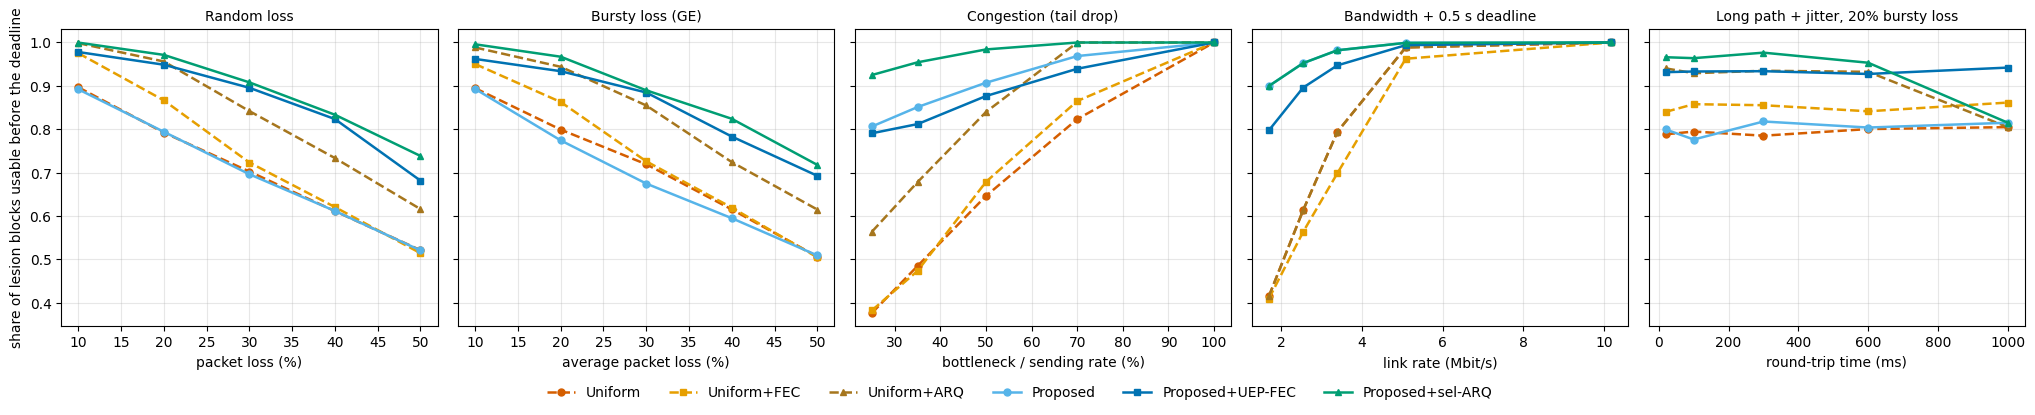

In [8]:
STYLE = {"Uniform": ("#D55E00", "--", "o"), "Uniform+FEC": ("#E69F00", "--", "s"), "Uniform+ARQ": ("#A6761D", "--", "^"),
         "Proposed": ("#56B4E9", "-", "o"), "Proposed+UEP-FEC": ("#0072B2", "-", "s"), "Proposed+sel-ARQ": ("#009E73", "-", "^"),
         "Conventional+UEP-FEC": ("#CC79A7", "-", "s"), "Oracle+UEP-FEC": ("#000000", "-", "s"),
         "Conventional+sel-ARQ": ("#CC79A7", "-", "^"), "Oracle+sel-ARQ": ("#000000", "-", "^")}
PANELS = [("iid", "Random loss", lambda v: 100 * v, "packet loss (%)"),
          ("burst", "Bursty loss (GE)", lambda v: 100 * v, "average packet loss (%)"),
          ("congestion", "Congestion (tail drop)", lambda v: 100 * v, "bottleneck / sending rate (%)"),
          ("deadline", "Bandwidth + 0.5 s deadline", lambda v: v * PKT_BYTES * 8 / 1e6, "link rate (Mbit/s)"),
          ("rtt", "Long path + jitter, 20% bursty loss", lambda v: v, "round-trip time (ms)")]

def draw(ax, sweep, metric, strategies=MAIN, xmap=lambda v: v):
    for s in strategies:
        d = SUM[(SUM.sweep == sweep) & (SUM.strategy == s)].sort_values("x")
        if d.empty or metric not in d: continue
        col, ls, mk = STYLE[s]; x = d.x.map(xmap)
        ax.plot(x, d[metric], color=col, ls=ls, marker=mk, ms=5, lw=1.8, label=s)
        if metric == "AUC" and "AUC_sd" in d and REPS > 1:
            ax.fill_between(x, d[metric] - d.AUC_sd, d[metric] + d.AUC_sd, color=col, alpha=.12)
    ax.grid(alpha=.3)

def five_panel(metric, ylabel, fname, ref=None):
    sw = [p for p in PANELS if p[0] in set(SUM.sweep)]
    fig, axs = plt.subplots(1, len(sw), figsize=(4.1 * len(sw), 3.9), sharey=True, squeeze=False); axs = axs[0]
    for ax, (name, title, xm, xl) in zip(axs, sw):
        draw(ax, name, metric, xmap=xm); ax.set_title(title, fontsize=10); ax.set_xlabel(xl)
        if ref is not None and np.isfinite(ref): ax.axhline(ref, color="k", ls=":", lw=1)
    axs[0].set_ylabel(ylabel); h, l = axs[0].get_legend_handles_labels()
    fig.legend(h, l, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(.5, -.07)); plt.tight_layout()
    plt.savefig(cfg.path("figures", fname), dpi=150, bbox_inches="tight"); plt.show()

five_panel("lesion_delivery", "share of lesion blocks usable before the deadline", "net3_fig2_lesion_delivery.png")

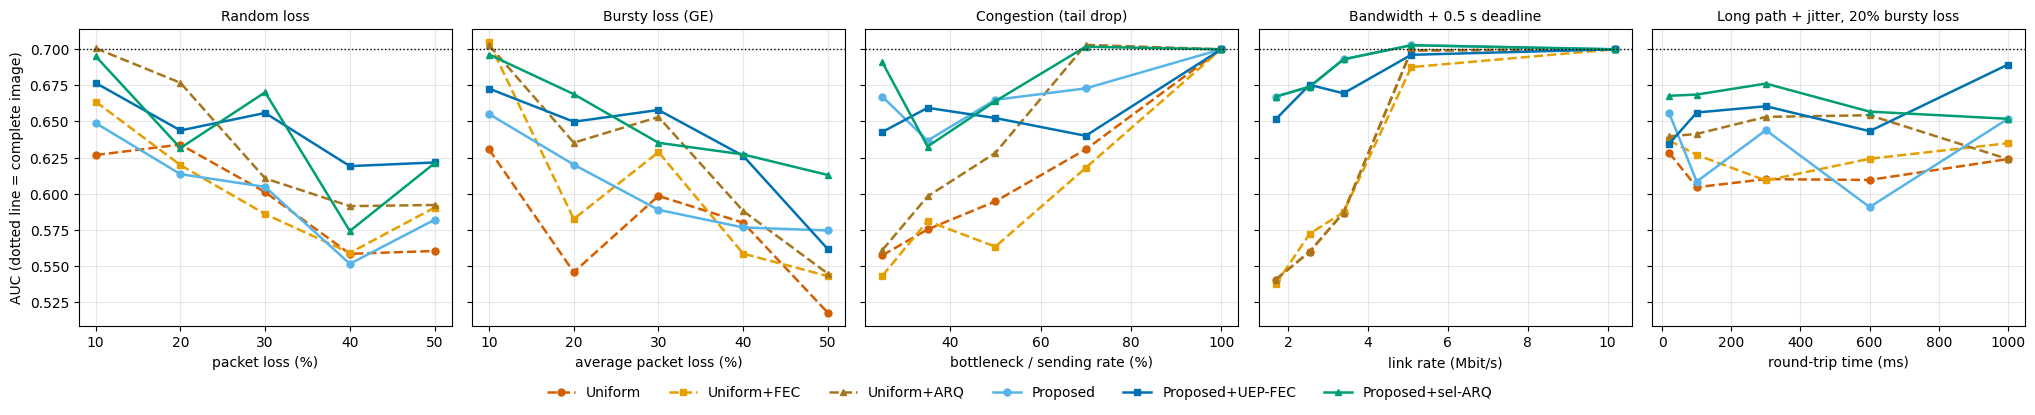

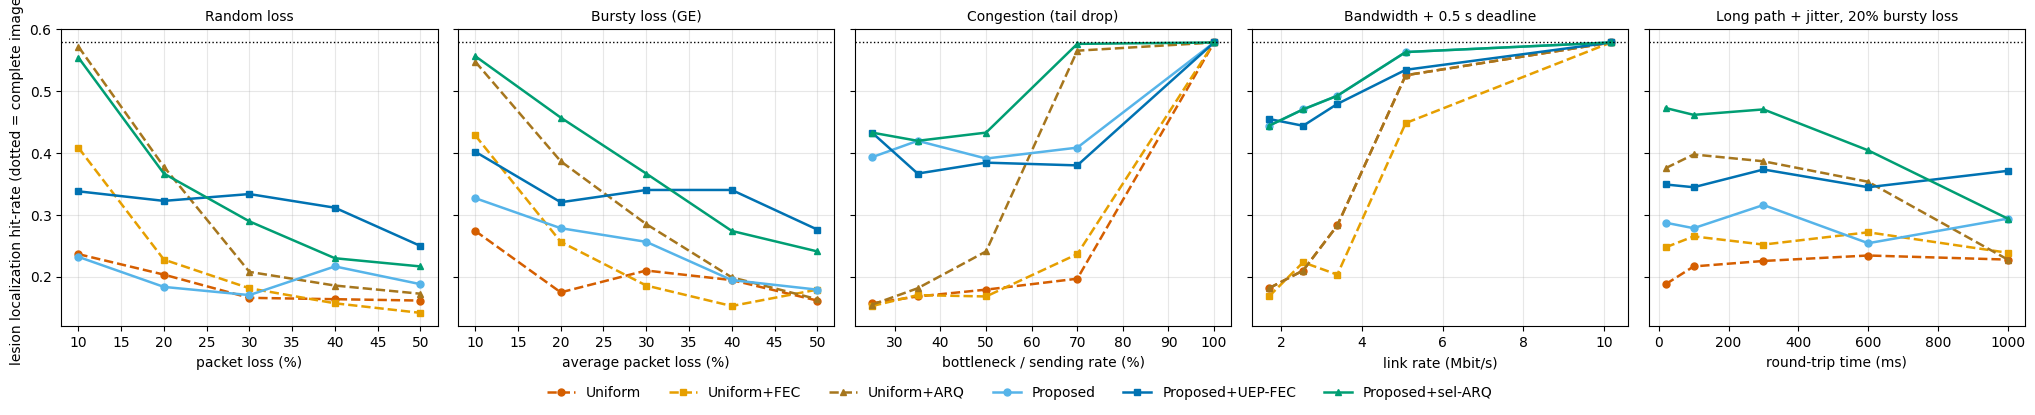

In [9]:
if RUN_RECEIVER:
    five_panel("AUC", "AUC (dotted line = complete image)", "net3_fig3_auc.png", ref=CLEAN_AUC)
    five_panel("loc_hit", "lesion localization hit-rate (dotted = complete image)", "net3_fig3b_hit.png", ref=CLEAN_HIT)

### Figure 4: how much overhead is needed? (bursty loss 30%)

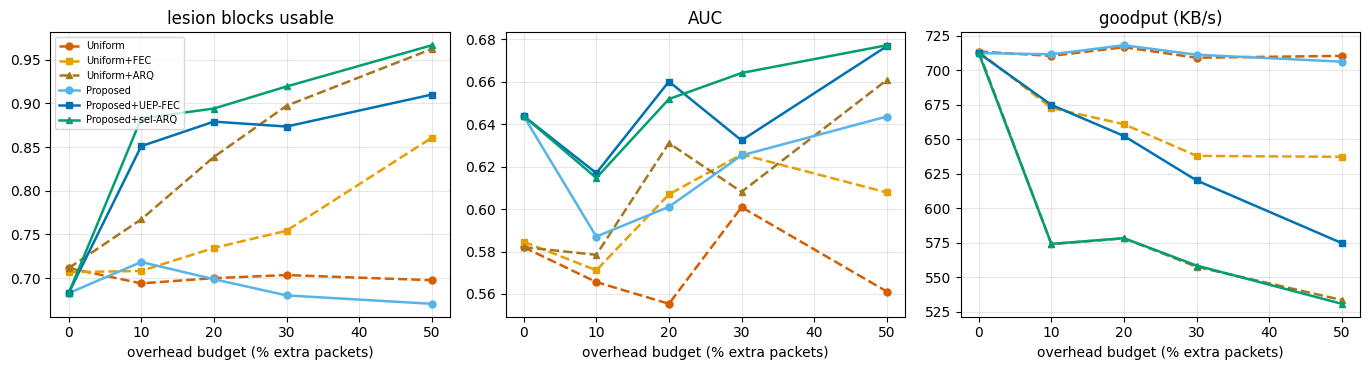

In [10]:
if "overhead" in set(SUM.sweep):
    mets = [("lesion_delivery", "lesion blocks usable")] + ([("AUC", "AUC")] if RUN_RECEIVER else []) + [("goodput_KBps", "goodput (KB/s)")]
    fig, axs = plt.subplots(1, len(mets), figsize=(4.6 * len(mets), 3.8), squeeze=False)
    for ax, (m, t) in zip(axs[0], mets):
        draw(ax, "overhead", m, xmap=lambda v: 100 * v); ax.set_xlabel("overhead budget (% extra packets)"); ax.set_title(t)
    axs[0][0].legend(fontsize=7); plt.tight_layout(); plt.savefig(cfg.path("figures", "net3_fig4_overhead.png"), dpi=150); plt.show()

### Figure 5: measured network behaviour in the combined profile
Bursty 20% loss, bottleneck at 70% of the sending rate, 60 ms one-way delay, 30 ms jitter, 1.5 s deadline. These numbers come out of the simulated packets (queueing + serialisation + propagation + jitter), not from the input parameters.

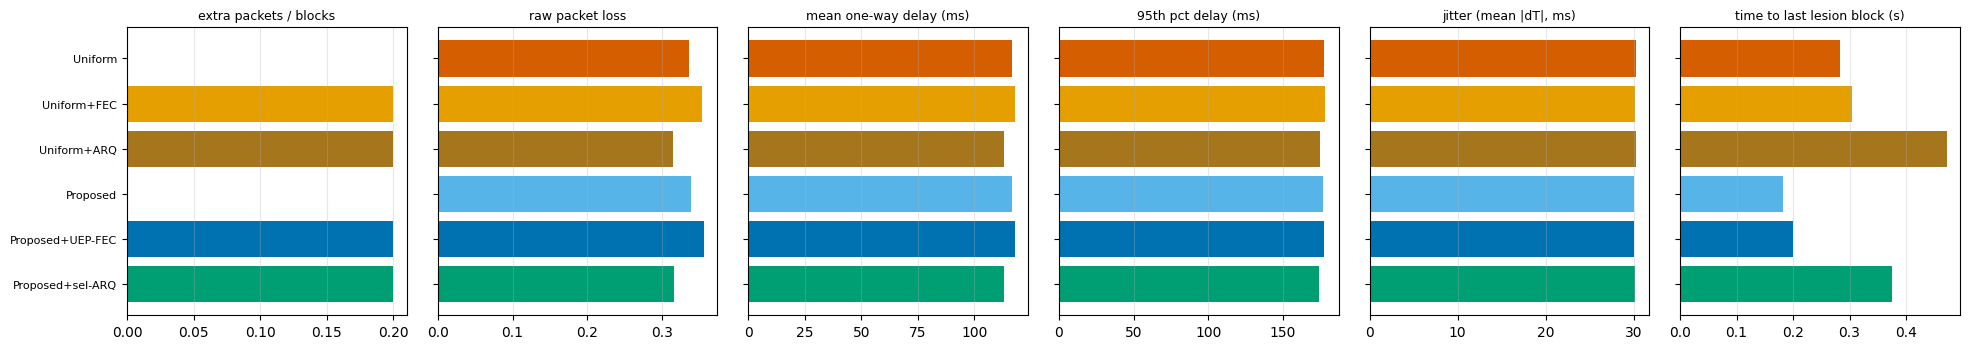

,AUC,lesion_delivery,block_delivery,overhead,pkt_loss,queue_drops,delay_ms,p95_delay_ms,jitter_ms,goodput_KBps,completion_s,lesion_time_s
strategy,,,,,,,,,,,,
Uniform,0.581,0.665,0.664,0.000,0.336,42.053,116.687,177.301,30.190,391.852,0.398,0.284
Uniform+FEC,0.607,0.665,0.680,0.200,0.353,56.254,117.872,178.394,30.135,379.968,0.420,0.305
Uniform+ARQ,0.628,0.819,0.823,0.199,0.314,42.053,113.287,174.498,30.230,291.388,0.661,0.472
Proposed,0.623,0.774,0.662,0.000,0.338,42.053,116.572,176.803,30.032,393.129,0.396,0.182
Proposed+UEP-FEC,0.634,0.889,0.652,0.200,0.356,56.254,117.787,177.657,30.013,352.260,0.435,0.200
Proposed+sel-ARQ,0.659,0.940,0.821,0.199,0.315,42.053,113.232,174.077,30.106,291.889,0.659,0.375


In [11]:
if "combined" in set(SUM.sweep):
    cb = SUM[SUM.sweep == "combined"].set_index("strategy").loc[MAIN]
    cols = [("overhead", "extra packets / blocks"), ("pkt_loss", "raw packet loss"), ("delay_ms", "mean one-way delay (ms)"), ("p95_delay_ms", "95th pct delay (ms)"),
            ("jitter_ms", "jitter (mean |dT|, ms)"), ("lesion_time_s", "time to last lesion block (s)")]
    fig, axs = plt.subplots(1, len(cols), figsize=(3.3 * len(cols), 3.6))
    for ax, (m, t) in zip(axs, cols):
        ax.barh(range(len(MAIN)), cb[m].values, color=[STYLE[s][0] for s in MAIN]); ax.set_yticks(range(len(MAIN)))
        ax.set_yticklabels(MAIN if ax is axs[0] else [], fontsize=8); ax.invert_yaxis(); ax.set_title(t, fontsize=9); ax.grid(axis="x", alpha=.3)
    plt.tight_layout(); plt.savefig(cfg.path("figures", "net3_fig5_network_metrics.png"), dpi=150); plt.show()
    display(cb[[k for k in ["AUC", "lesion_delivery", "block_delivery", "overhead", "pkt_loss", "queue_drops", "delay_ms", "p95_delay_ms", "jitter_ms",
                            "goodput_KBps", "completion_s", "lesion_time_s"] if k in cb]].round(3))

## 5. Does the clinical guidance matter? (ablation, bursty loss 30%)
Same mechanism, different source of priority: classifier-guided map (**Proposed**), generic block contrast (**Conventional**), true mask (**Oracle**, upper bound). `tier_recall` = share of lesion blocks that land in the protected top-ranked tier.

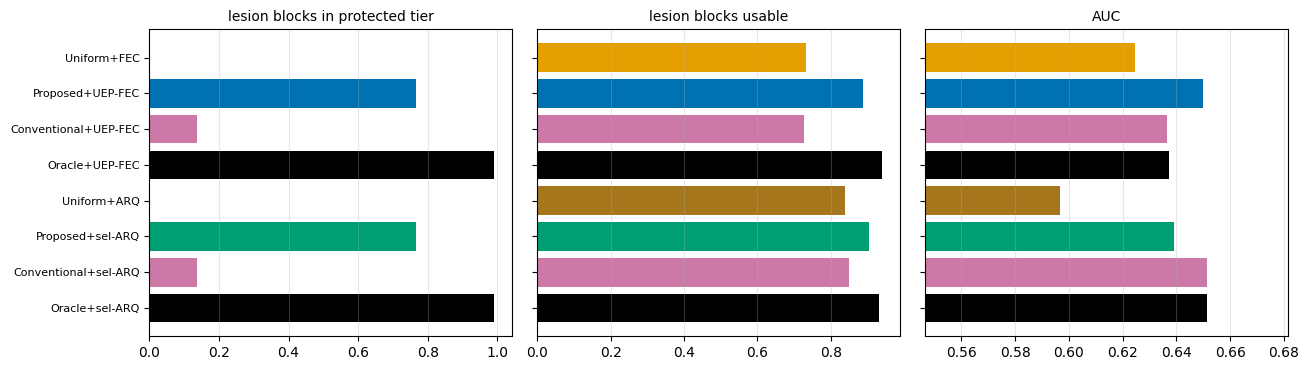

,AUC,loc_hit,lesion_delivery,tier_recall,overhead,goodput_KBps
strategy,,,,,,
Uniform+FEC,0.625,0.203,0.731,NaN,0.200,656.499
Proposed+UEP-FEC,0.650,0.364,0.887,0.768,0.200,646.765
Conventional+UEP-FEC,0.637,0.203,0.726,0.137,0.200,646.765
Oracle+UEP-FEC,0.637,0.338,0.941,0.992,0.200,646.765
Uniform+ARQ,0.597,0.252,0.840,NaN,0.197,574.074
Proposed+sel-ARQ,0.639,0.355,0.905,0.768,0.197,571.875
Conventional+sel-ARQ,0.651,0.309,0.849,0.137,0.197,571.875
Oracle+sel-ARQ,0.651,0.309,0.932,0.992,0.197,571.875


In [12]:
if "ablation" in set(SUM.sweep):
    ab = SUM[SUM.sweep == "ablation"].set_index("strategy").loc[ABL]
    mets = [("tier_recall", "lesion blocks in protected tier"), ("lesion_delivery", "lesion blocks usable")] + ([("AUC", "AUC")] if RUN_RECEIVER else [])
    fig, axs = plt.subplots(1, len(mets), figsize=(4.4 * len(mets), 3.8))
    for ax, (m, t) in zip(np.atleast_1d(axs), mets):
        vals = ab[m].fillna(0).values; ax.barh(range(len(ABL)), vals, color=[STYLE[s][0] for s in ABL]); ax.set_yticks(range(len(ABL)))
        ax.set_yticklabels(ABL if m == mets[0][0] else [], fontsize=8); ax.invert_yaxis(); ax.set_title(t, fontsize=10); ax.grid(axis="x", alpha=.3)
        if m == "AUC":
            ax.set_xlim(max(.5, np.nanmin(vals) - .05), min(1, np.nanmax(vals) + .03)); ax.axvline(CLEAN_AUC, color="k", ls=":", lw=1)
    plt.tight_layout(); plt.savefig(cfg.path("figures", "net3_fig6_ablation.png"), dpi=150); plt.show()
    display(ab[[k for k in ["AUC", "loc_hit", "lesion_delivery", "tier_recall", "overhead", "goodput_KBps"] if k in ab]].round(3))

In [13]:
# patient-level bootstrap at bursty 30% loss: are the differences real?
if RUN_RECEIVER and "ablation" in set(SUM.sweep):
    ra = R[R.sweep == "ablation"]
    P_ = ra.groupby(["strategy", "img"]).agg(p=("p", "mean"), y=("y", "first"), pat=("patient_id", "first")).reset_index()
    get = lambda s: P_[P_.strategy == s].sort_values("img")
    rows = []
    for s in ABL:
        g = get(s); a, lo, hi = bootstrap_ci(auc_safe, g.y.values, g.p.values, g.pat.values, 500)
        rows.append(dict(kind="AUC", a=s, b="", value=a, ci_low=lo, ci_high=hi, p_value=np.nan))
    for a_, b_ in [("Proposed+UEP-FEC", "Uniform+FEC"), ("Proposed+sel-ARQ", "Uniform+ARQ"), ("Proposed+UEP-FEC", "Conventional+UEP-FEC"),
                   ("Oracle+UEP-FEC", "Proposed+UEP-FEC"), ("Proposed+UEP-FEC", "Proposed+sel-ARQ")]:
        ga, gb = get(a_), get(b_); v, lo, hi, p = paired_bootstrap_diff(auc_safe, ga.y.values, ga.p.values, gb.p.values, ga.pat.values, 500)
        rows.append(dict(kind="AUC difference", a=a_, b=b_, value=v, ci_low=lo, ci_high=hi, p_value=p))
    BT = pd.DataFrame(rows); BT.to_csv(cfg.path("results", "net3_bootstrap.csv"), index=False); display(BT.round(3))

,kind,a,b,value,ci_low,ci_high,p_value
0,AUC,Uniform+FEC,,0.625,0.569,0.678,NaN
1,AUC,Proposed+UEP-FEC,,0.650,0.591,0.706,NaN
2,AUC,Conventional+UEP-FEC,,0.637,0.580,0.694,NaN
3,AUC,Oracle+UEP-FEC,,0.637,0.580,0.691,NaN
4,AUC,Uniform+ARQ,,0.597,0.536,0.659,NaN
5,AUC,Proposed+sel-ARQ,,0.639,0.576,0.695,NaN
6,AUC,Conventional+sel-ARQ,,0.651,0.592,0.707,NaN
7,AUC,Oracle+sel-ARQ,,0.651,0.595,0.703,NaN
8,AUC difference,Proposed+UEP-FEC,Uniform+FEC,0.025,-0.034,0.085,0.424
9,AUC difference,Proposed+sel-ARQ,Uniform+ARQ,0.042,-0.011,0.102,0.132


### Figure 7: one image, three strategies (bursty loss 30%, same random seed)

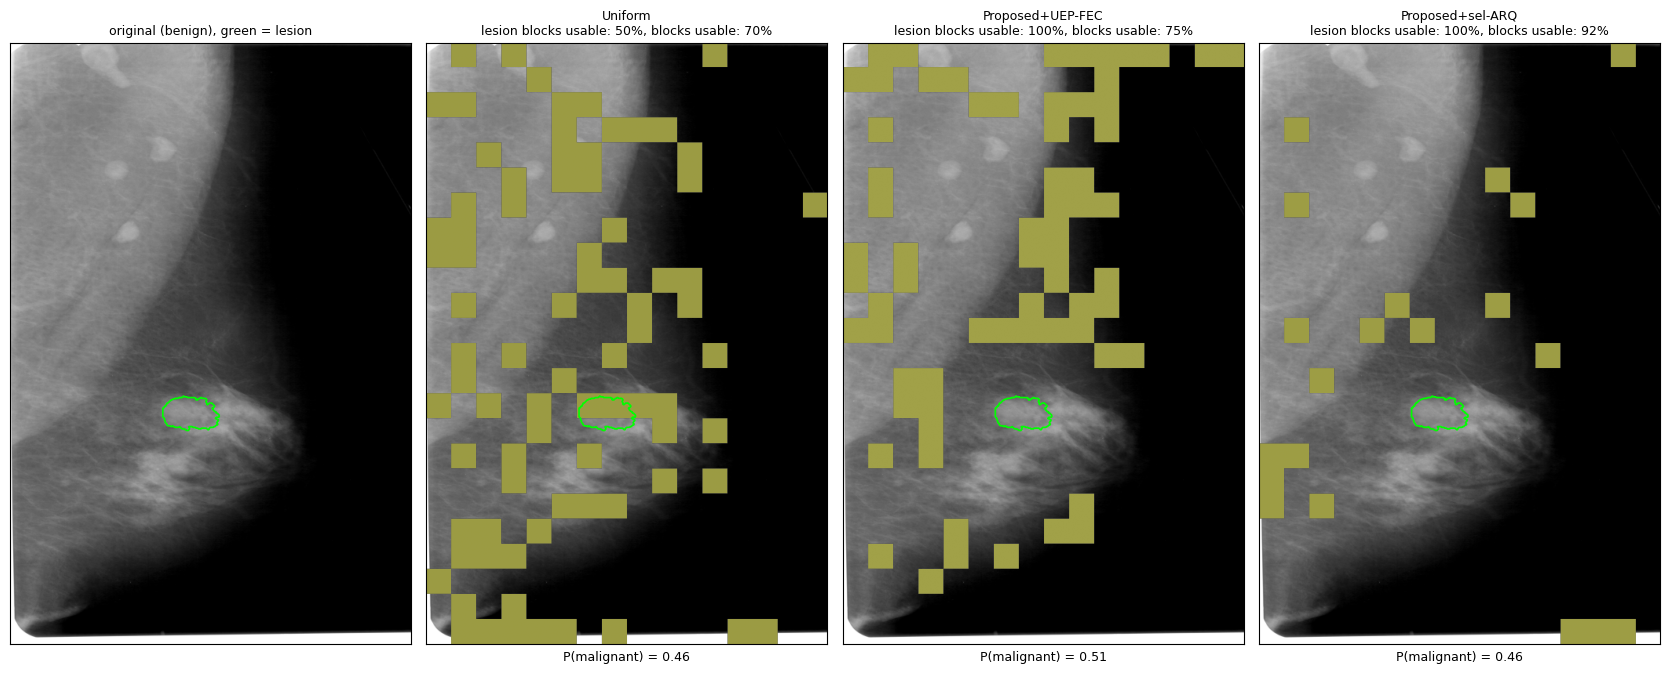

In [14]:
def example_figure(i, sc, strategies=("Uniform", "Proposed+UEP-FEC", "Proposed+sel-ARQ"), seed=7):
    fig, axs = plt.subplots(1, len(strategies) + 1, figsize=(4.2 * (len(strategies) + 1), 7.2)); recs = []
    axs[0].imshow(img01[i], cmap="gray", vmin=0, vmax=1); axs[0].contour(GT[i], levels=[.5], colors="lime", linewidths=1.2)
    axs[0].set_title(f"original ({'malignant' if Y[i] else 'benign'}), green = lesion", fontsize=9)
    for ax, s in zip(axs[1:], strategies):
        src, om, pr = STRATS[s]; imp = IMPS[src][i]; res = transmit(imp, om, pr, sc, np.random.default_rng(seed))
        lost = (imp >= 0) & ~res["recv"]; rec, _ = apply_loss(img01[i], lost, BLK, cfg.recon); recs.append(rec)
        ax.imshow(rec, cmap="gray", vmin=0, vmax=1); ov = np.kron(lost, np.ones((BLK, BLK)))
        ax.imshow(np.ma.masked_where(ov == 0, ov), cmap="autumn", alpha=.35, vmin=0, vmax=1); ax.contour(GT[i], levels=[.5], colors="lime", linewidths=1.2)
        ax.set_title(f"{s}\nlesion blocks usable: {res['recv'][LES[i]].mean():.0%}, blocks usable: {res['stats']['block_delivery']:.0%}", fontsize=9)
    if RUN_RECEIVER:
        r = diagnose_all(receiver, np.stack(recs))
        for ax, s, pp in zip(axs[1:], strategies, r["p"]): ax.set_xlabel(f"P(malignant) = {pp:.2f}", fontsize=9)
    for ax in axs: ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout(); plt.savefig(cfg.path("figures", "net3_fig7_example.png"), dpi=150); plt.show()

example_figure(int(np.argsort([l.sum() for l in LES])[N // 2]), S(loss_model="ge", loss=.3))

## 6. Headline numbers

In [15]:
def headline(sweep, x):
    d = SUM[(SUM.sweep == sweep) & np.isclose(SUM.x.astype(float), x)].set_index("strategy")
    return d[[k for k in ["AUC", "loc_hit", "lesion_delivery", "block_delivery", "overhead", "delay_ms", "jitter_ms", "goodput_KBps", "completion_s"] if k in d]].round(3)
if RUN_RECEIVER: print(f"complete image: AUC {CLEAN_AUC:.3f}")
for sw, x, t in [("burst", .3, "bursty loss 30%"), ("iid", .3, "random loss 30%"), ("congestion", .5, "bottleneck at 50% of sending rate"), ("combined", 0, "combined mobile-like profile")]:
    if sw in set(SUM.sweep): display(headline(sw, x).rename_axis(t))

complete image: AUC 0.700


,AUC,loc_hit,lesion_delivery,block_delivery,overhead,delay_ms,jitter_ms,goodput_KBps,completion_s
bursty loss 30%,,,,,,,,,
Uniform,0.599,0.210,0.719,0.699,0.000,30.818,4.984,712.703,0.231
Uniform+FEC,0.629,0.185,0.726,0.725,0.200,30.812,4.976,651.297,0.262
Uniform+ARQ,0.653,0.285,0.855,0.840,0.197,30.827,4.998,576.933,0.342
Proposed,0.589,0.256,0.675,0.701,0.000,30.802,4.963,713.421,0.231
Proposed+UEP-FEC,0.658,0.340,0.885,0.744,0.200,30.795,4.963,647.860,0.270
Proposed+sel-ARQ,0.635,0.366,0.890,0.837,0.198,30.809,4.980,576.514,0.341


,AUC,loc_hit,lesion_delivery,block_delivery,overhead,delay_ms,jitter_ms,goodput_KBps,completion_s
random loss 30%,,,,,,,,,
Uniform,0.601,0.166,0.703,0.700,0.0,30.834,5.010,708.907,0.232
Uniform+FEC,0.586,0.181,0.723,0.721,0.2,30.836,5.010,643.018,0.264
Uniform+ARQ,0.611,0.208,0.842,0.839,0.2,30.836,5.010,582.945,0.337
Proposed,0.605,0.170,0.696,0.698,0.0,30.835,5.007,705.203,0.233
Proposed+UEP-FEC,0.656,0.333,0.896,0.750,0.2,30.847,5.026,648.760,0.272
Proposed+sel-ARQ,0.670,0.289,0.908,0.838,0.2,30.847,5.026,582.676,0.337


,AUC,loc_hit,lesion_delivery,block_delivery,overhead,delay_ms,jitter_ms,goodput_KBps,completion_s
bottleneck at 50% of sending rate,,,,,,,,,
Uniform,0.595,0.179,0.647,0.627,0.0,69.873,5.055,524.583,0.280
Uniform+FEC,0.563,0.168,0.679,0.677,0.2,71.144,5.036,512.814,0.309
Uniform+ARQ,0.628,0.241,0.840,0.827,0.2,65.287,5.288,456.669,0.423
Proposed,0.665,0.391,0.907,0.627,0.0,69.875,5.044,524.300,0.280
Proposed+UEP-FEC,0.652,0.384,0.877,0.584,0.2,71.163,5.052,428.784,0.319
Proposed+sel-ARQ,0.664,0.433,0.984,0.827,0.2,65.301,5.281,456.098,0.424


,AUC,loc_hit,lesion_delivery,block_delivery,overhead,delay_ms,jitter_ms,goodput_KBps,completion_s
combined mobile-like profile,,,,,,,,,
Uniform,0.581,0.196,0.665,0.664,0.000,116.687,30.190,391.852,0.398
Uniform+FEC,0.607,0.192,0.665,0.680,0.200,117.872,30.135,379.968,0.420
Uniform+ARQ,0.628,0.223,0.819,0.823,0.199,113.287,30.230,291.388,0.661
Proposed,0.623,0.296,0.774,0.662,0.000,116.572,30.032,393.129,0.396
Proposed+UEP-FEC,0.634,0.369,0.889,0.652,0.200,117.787,30.013,352.260,0.435
Proposed+sel-ARQ,0.659,0.408,0.940,0.821,0.199,113.232,30.106,291.889,0.659


## 7. How to read these results (and what not to claim)
- **Priority order alone does nothing against random or bursty loss** (Proposed = Uniform in Figures 2 and 3, left panels). This is expected: the channel does not care which packet it kills. It helps only when a *queue or a deadline* decides which packets are lost, because the lesion blocks are sent first (congestion and deadline panels).
- **Protection is what buys resilience**, and the clinical ranking decides where the same overhead is spent. Compare *Proposed+UEP-FEC* with *Uniform+FEC* (equal overhead) and with the Conventional / Oracle ablations.
- **FEC adds load.** Under congestion or a tight deadline the extra packets can hurt (look at the deadline panel). Report that honestly.
- **ARQ needs time.** On the long path (right panel) retransmissions arrive after the deadline and ARQ falls back to the plain result; FEC does not depend on the round-trip time.
- The proposed system needs the lesion ranking **before** sending, i.e. the localizer and the saliency run at the sender. The ranking quality (`tier_recall`) bounds what any protection scheme can achieve.

## 8. Limits of this simulation, and how to validate it
- Idealised erasure code, lossless NACKs, fixed-rate pacing, no congestion control, constant header overhead, loss models that are standard but synthetic, no cross traffic.
- All delay, jitter and throughput values are outputs of this packet-level model. They show how the strategies compare under the same modelled path, not what a real network would measure.
- To strengthen the networking claim: replay the same packet streams through Linux `tc netem` / Mininet (or ns-3) with a real UDP sender, record the per-packet arrival traces, and feed those traces to the receiver instead of the model above; then compare with the numbers here.